# EDA dataset data_generator — run `data-v3-20261107`

Notebook ini menganalisis dataset hasil `run_experiment.py` (300 sesi, PC lab RTX 5060 Ti) sebelum
dipakai untuk training detector. **Satu sesi** = satu Pod job; **satu baris** = satu sampel telemetri
(interval 5 s).

**Cara pakai:** buka di VS Code, pilih kernel Python dari `misuse/venv`, lalu *Run All*. Ganti
`DATA_DIR` di sel konfigurasi untuk menganalisis run lain.

| Bagian | Isi |
|---|---|
| 1 | Ringkasan dataset: jumlah sesi per skenario, durasi, sesi yang tersaring validasi |
| 2 | Kolom, nilai kosong, kolom konstan |
| 3 | Fitur per sesi dan distribusinya per skenario |
| 4 | Contoh time series per skenario |
| 5 | Sidecar vs Prometheus (lag, artefak awal sesi) |
| 6 | Baseline berbasis aturan `policy.json` |
| 7 | Keterpisahan fitur dan potensi jalan pintas label |
| 8 | Hard negative: sesi benign yang mirip R7 |
| 9 | Korelasi antar fitur |
| 10 | Ringkasan untuk rekayasa fitur |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

# --- Konfigurasi ---------------------------------------------------------------
RUN = "data-v3-20261107"
CANDIDATES = [Path.cwd() / RUN, Path.cwd() / "misuse/boilerplate/data_generator" / RUN,
              Path("/home/cloudx/ta-cloudx/misuse/boilerplate/data_generator") / RUN]
DATA_DIR = next((p for p in CANDIDATES if (p / "dataset.csv").exists()), CANDIDATES[0])
WARMUP_SEC = 20        # sama dengan validate_dataset.py: lewati fase import/inisialisasi job
PROM_WARMUP_SEC = 60   # kolom prom_*: rate()[1m] dan scrape 15/30 s butuh ~60 s untuk stabil
print("DATA_DIR =", DATA_DIR)

DATA_DIR = /home/cloudx/ta-cloudx/misuse/boilerplate/data_generator/data-v3-20261107


In [2]:
df = pd.read_csv(DATA_DIR / "dataset.csv", parse_dates=["timestamp"])
plan = json.load(open(DATA_DIR / "plan.json"))
policy = json.load(open(DATA_DIR / "policy.json"))
gt = pd.read_csv(DATA_DIR / "ground_truth_check.csv").set_index("session_id")
verified_ids = set(pd.read_csv(DATA_DIR / "dataset_verified.csv", usecols=["session_id"]).session_id)

df["verified"] = df["session_id"].isin(verified_ids)
SHORT = {j: j.replace("benign_", "").replace("misuse_", "") for j in df.job_type.unique()}
print(f"{len(df):,} baris | {df.session_id.nunique()} sesi | {df.shape[1]} kolom")
print(f"rencana: {len(plan['sessions'])} sesi, seed {plan['args']['seed']}, "
      f"duration_scale {plan['args']['duration_scale']}, GPU {plan['gpu']['name']}")
print("policy.json:", policy)

13,760 baris | 300 sesi | 74 kolom
rencana: 300 sesi, seed 42, duration_scale 0.5, GPU NVIDIA GeForce RTX 5060 Ti
policy.json: {'idle_timeout_sec': 120, 'max_concurrent_sessions': 2, 'mem_budget_mb': 16311, 'quota_fracs': [0.5, 0.75]}


## 1. Ringkasan dataset
Jumlah sesi per skenario, durasi nyata (`session_age_sec` maksimum) dibanding durasi rencana
(`param_duration_sec`), dan sesi yang **tidak lolos** cek ground truth (tidak masuk
`dataset_verified.csv`).

In [3]:
per_sess = df.groupby("session_id").agg(
    label=("label", "first"), job_type=("job_type", "first"), scenario_code=("scenario_code", "first"),
    label_class=("label_class", "first"), verified=("verified", "first"), rows=("timestamp", "size"),
    duration_s=("session_age_sec", "max"), planned_s=("param_duration_sec", "first"))
per_sess["overshoot_s"] = per_sess.duration_s - per_sess.planned_s

summary = per_sess.groupby(["label", "scenario_code", "job_type"]).agg(
    sesi=("rows", "size"), verified=("verified", "sum"), baris_median=("rows", "median"),
    durasi_median_s=("duration_s", "median"), overshoot_maks_s=("overshoot_s", "max"))
display(summary)
print("label:", per_sess.label.value_counts().to_dict())
print("kelas misuse:", per_sess[per_sess.label == "misuse"].label_class.value_counts().to_dict())

excluded = gt[gt.status != "lolos"][["job_type", "status", "cek_gagal"]]
print(f"\nsesi tidak lolos verifikasi: {len(excluded)}")
display(excluded)

sesi  verified  baris_median  durasi_median_s  overshoot_maks_s
label  scenario_code job_type                                                                                        
benign BENIGN        benign_batch_inference             51        51        38.000          191.400            12.400
                     benign_cnn_training                51        50        56.000          281.300             8.300
                     benign_data_pipeline_training      51        36        54.000          271.400             5.400
                     benign_eda_notebook                51        51        42.000          211.400             3.400
                     benign_interactive_gpu_notebook    51        51        44.000          221.400            60.400
misuse P5            misuse_gpu_monopolization           5         5        84.000          421.300             9.300
       R1            misuse_idle_hoarding                5         5        47.000          236.300             2.300
       R2            misuse_idle_session                 5         5        46.000          231.300             5.400
       R3            misuse_quota_exceed                 4         4        36.500          183.800             2.300
       R4            misuse_overprovisioning             4         4        43.000          216.400             9.400
       R5            misuse_zombie_job                   4         4        34.000          171.300             9.300
       R6            misuse_concurrent_sessions          5         5        46.000          231.300            28.300
       R7            misuse_inefficient_gpu              4         4        35.000          176.400             1.400
       S1            misuse_disguised_pattern            5         5        50.000          251.200             1.300
                     misuse_synthetic_load               4         4        32.500          163.800             2.300

label: {'benign': 255, 'misuse': 45}
kelas misuse: {'K2': 28, 'K3': 9, 'K1': 8}

sesi tidak lolos verifikasi: 16


,job_type,status,cek_gagal
session_id,,,
benign_cnn_training_0154,benign_cnn_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0013,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0026,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0056,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0058,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0123,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0144,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0146,benign_data_pipeline_training,gagal,bukan_pola_R7
benign_data_pipeline_training_0182,benign_data_pipeline_training,gagal,bukan_pola_R7


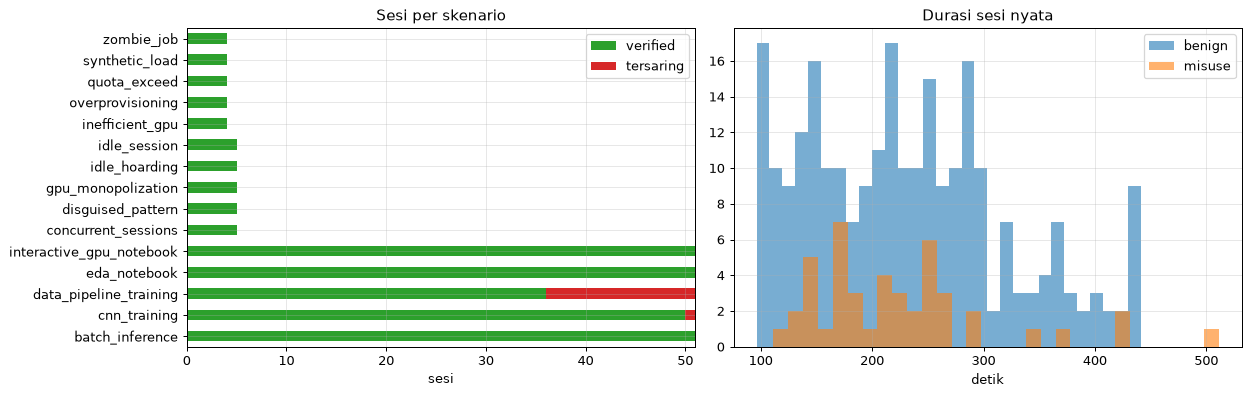

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cnt = per_sess.groupby(["job_type", "verified"]).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
cnt.index = [SHORT[j] for j in cnt.index]
cnt.plot.barh(stacked=True, ax=axes[0], color=["tab:green", "tab:red"])
axes[0].legend(["verified", "tersaring"]); axes[0].set_title("Sesi per skenario"); axes[0].set_xlabel("sesi")
for lab, color in (("benign", "tab:blue"), ("misuse", "tab:orange")):
    axes[1].hist(per_sess.loc[per_sess.label == lab, "duration_s"], bins=30, alpha=0.6, label=lab, color=color)
axes[1].set_title("Durasi sesi nyata"); axes[1].set_xlabel("detik"); axes[1].legend()
plt.tight_layout(); plt.show()

## 2. Kolom dan nilai kosong
Kelompok kolom:
- **meta/label**: `session_id`, `label`, `job_type`, `scenario_code`, `label_class`, `user_id`, `quota_mem_mb`
- **sidecar** (psutil + nvidia-smi di dalam Pod): CPU, memori, IO kumulatif, GPU (utilisasi = rata-rata per interval 5 s)
- **konteks** (sidecar): umur sesi, umur aktivitas terakhir
- **Prometheus** (`prom_*`): cAdvisor (scrape 15 s) dan kube-state-metrics (scrape 30 s), diambil runner dengan `query_range`
- **`param_*`**: parameter yang diundi di `plan.json` = *ground truth*, **bukan fitur**; kosong untuk skenario yang tidak memiliki parameter tersebut

In [5]:
META = ["timestamp", "session_id", "label", "job_type", "scenario_code", "label_class", "user_id", "quota_mem_mb"]
SIDECAR = ["cpu_pct", "mem_rss_mb", "io_read_mb", "io_write_mb", "num_alive_processes", "gpu_util_pct",
           "gpu_mem_util_pct", "gpu_mem_used_mb_device", "gpu_mem_used_mb_process", "gpu_mem_total_mb"]
CONTEXT = ["session_age_sec", "last_activity_age_sec", "gpu_alloc_sec"]
PROM = [c for c in df.columns if c.startswith("prom_")]
PARAM = [c for c in df.columns if c.startswith("param_")]
group_of = {**{c: "meta" for c in META}, **{c: "sidecar" for c in SIDECAR},
            **{c: "konteks" for c in CONTEXT}, **{c: "prometheus" for c in PROM}}

info = pd.DataFrame({c: {"kelompok": group_of[c], "kosong_%": 100 * df[c].isna().mean(),
                         "nilai_unik": df[c].nunique(dropna=True)} for c in META + SIDECAR + CONTEXT + PROM}).T
info = info.astype({"kosong_%": float, "nilai_unik": int})
info["konstan"] = info.nilai_unik <= 1
display(info[(info["kosong_%"] > 0) | info.konstan].sort_values("kosong_%", ascending=False))
print("identik dengan session_age_sec:",
      [c for c in SIDECAR + CONTEXT if c != "session_age_sec" and np.allclose(df[c], df.session_age_sec, equal_nan=False)])
print(f"kolom param_* (ground truth, bukan fitur): {len(PARAM)}")

,kelompok,kosong_%,nilai_unik,konstan
prom_cpu_limit_cores,prometheus,100.000,0,True
prom_mem_limit_mb,prometheus,100.000,0,True
prom_io_write_mb,prometheus,5.603,6999,False
prom_cpu_cores,prometheus,5.603,8626,False
prom_cpu_pct,prometheus,5.603,9119,False
prom_io_read_mb,prometheus,5.603,4453,False
prom_net_rx_packets,prometheus,5.516,2325,False
prom_net_rx_mb,prometheus,5.516,18,False
prom_net_tx_mb,prometheus,5.516,18,False
prom_net_tx_packets,prometheus,5.516,5261,False


identik dengan session_age_sec: ['gpu_alloc_sec']
kolom param_* (ground truth, bukan fitur): 32


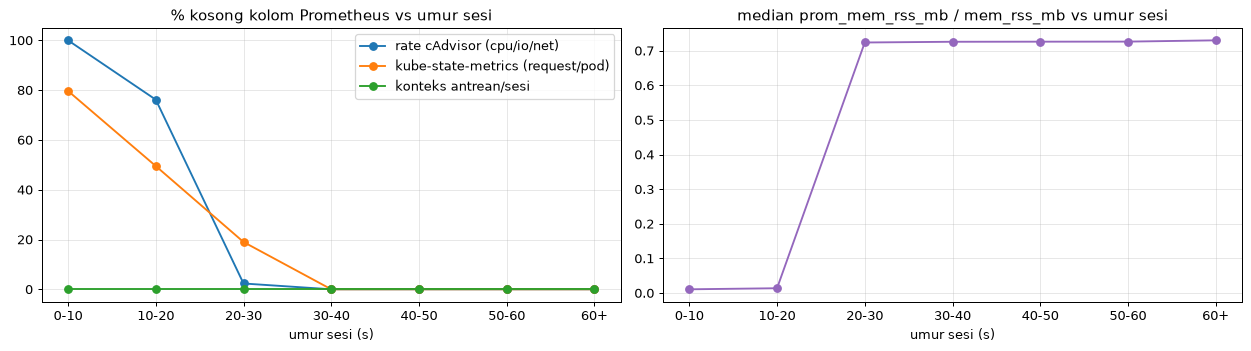

In [6]:
# Nilai kosong kolom Prometheus menurut umur sesi: hanya di awal sesi
bins = [0, 10, 20, 30, 40, 50, 60, np.inf]
age_bin = pd.cut(df.session_age_sec, bins, labels=["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60+"])
fam = {"rate cAdvisor (cpu/io/net)": "prom_cpu_pct", "kube-state-metrics (request/pod)": "prom_cpu_request_cores",
       "konteks antrean/sesi": "prom_user_active_sessions"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, col in fam.items():
    axes[0].plot(df[col].isna().groupby(age_bin, observed=False).mean() * 100, marker="o", label=name)
axes[0].set_title("% kosong kolom Prometheus vs umur sesi"); axes[0].set_xlabel("umur sesi (s)"); axes[0].legend()
# Kolom memori Prometheus tidak kosong, tetapi basi (~0) di awal sesi
ratio = (df.prom_mem_rss_mb / df.mem_rss_mb).groupby(age_bin, observed=False).median()
axes[1].plot(ratio, marker="o", color="tab:purple")
axes[1].set_title("median prom_mem_rss_mb / mem_rss_mb vs umur sesi"); axes[1].set_xlabel("umur sesi (s)")
plt.tight_layout(); plt.show()

## 3. Fitur per sesi
Satu baris per sesi. Kolom sidecar dihitung setelah `WARMUP_SEC`, kolom Prometheus setelah
`PROM_WARMUP_SEC`. IO diubah dari kumulatif menjadi **laju** (MB/s), dan VRAM juga dinyatakan relatif
terhadap kuota sesi (`quota_mem_mb`). Ini fitur eksplorasi, bukan fitur final model.

In [7]:
def first_valid(s):
    s = s.dropna()
    return s.iloc[0] if len(s) else np.nan


def session_features(data):
    rows = []
    for sid, d in data.groupby("session_id", sort=False):
        d = d.sort_values("session_age_sec")
        st = d[d.session_age_sec > WARMUP_SEC]
        st = st if len(st) >= 2 else d
        pw = d[d.session_age_sec > PROM_WARMUP_SEC]
        pw = pw if len(pw) else d
        span = max(st.session_age_sec.iloc[-1] - st.session_age_sec.iloc[0], 1e-9)
        quota = d.quota_mem_mb.iloc[0]
        rows.append({
            "session_id": sid, "label": d.label.iloc[0], "job_type": d.job_type.iloc[0],
            "scenario_code": d.scenario_code.iloc[0], "label_class": d.label_class.iloc[0],
            "verified": d.verified.iloc[0], "duration_s": d.session_age_sec.max(), "quota_mem_mb": quota,
            "gpu_util_mean": st.gpu_util_pct.mean(), "gpu_util_p90": st.gpu_util_pct.quantile(0.9),
            "gpu_util_std": st.gpu_util_pct.std(), "gpu_memutil_mean": st.gpu_mem_util_pct.mean(),
            "cpu_median": st.cpu_pct.median(), "cpu_std": st.cpu_pct.std(),
            "mem_rss_median": st.mem_rss_mb.median(),
            "vram_max_mb": d.gpu_mem_used_mb_device.max(), "vram_median_mb": st.gpu_mem_used_mb_device.median(),
            "vram_quota_ratio": d.gpu_mem_used_mb_device.max() / quota,
            "io_read_mbps": (st.io_read_mb.iloc[-1] - st.io_read_mb.iloc[0]) / span,
            "io_write_mbps": (st.io_write_mb.iloc[-1] - st.io_write_mb.iloc[0]) / span,
            "last_activity_max": d.last_activity_age_sec.max(),
            "activity_resets": int((d.last_activity_age_sec.diff() < -0.5).sum()),
            "queue_max": d.prom_queue_length.max(), "queue_wait_max": d.prom_queue_wait_max_sec.max(),
            "sessions_max": d.prom_user_active_sessions.max(),
            "cpu_request": first_valid(d.prom_cpu_request_cores), "mem_request_mb": first_valid(d.prom_mem_request_mb),
            "prom_cpu_pct_median": pw.prom_cpu_pct.median(), "prom_mem_rss_median": pw.prom_mem_rss_mb.median(),
            "prom_net_rx_mbps": pw.prom_net_rx_mb.median(),
        })
    return pd.DataFrame(rows).set_index("session_id")


sf = session_features(df)
FEATURES = [c for c in sf.columns if c not in ("label", "job_type", "scenario_code", "label_class", "verified")]
print(f"{len(sf)} sesi x {len(FEATURES)} fitur eksplorasi")
display(sf.groupby(["scenario_code", "job_type"])[
    ["gpu_util_mean", "cpu_median", "vram_quota_ratio", "io_read_mbps", "last_activity_max",
     "queue_max", "sessions_max", "cpu_request", "duration_s"]].median())

300 sesi x 24 fitur eksplorasi


gpu_util_mean  cpu_median  vram_quota_ratio  io_read_mbps  last_activity_max  queue_max  sessions_max  cpu_request  duration_s
scenario_code job_type                                                                                                                                                       
BENIGN        benign_batch_inference                   4.800       0.500             0.082         0.000             11.100      0.000         1.000        1.000     191.400
              benign_cnn_training                     96.368      99.000             0.057         0.001              1.000      1.000         1.000        1.000     281.300
              benign_data_pipeline_training           92.506      98.400             0.037         2.142             14.200      1.000         1.000        2.000     271.400
              benign_eda_notebook                      0.000       3.600             0.000         0.000              1.800      0.000         1.000        2.000     211.400
              benign_interactive_gpu_notebook          8.152       0.000             0.023         0.000             48.300      0.000         2.000        1.000     221.400
P5            misuse_gpu_monopolization              100.000      99.800             0.106         0.000              3.200      3.000         1.000        1.000     421.300
R1            misuse_idle_hoarding                     0.000       0.000             0.673         0.000             73.900      2.000         1.000        1.000     236.300
R2            misuse_idle_session                      1.831       0.000             0.017         0.000            182.100      0.000         2.000        1.000     231.300
R3            misuse_quota_exceed                      1.623       0.000             1.481         0.000              8.700      0.000         1.000        2.000     183.800
R4            misuse_overprovisioning                  0.002       0.100             0.017         0.001              9.550      0.000         1.000        5.000     216.400
R5            misuse_zombie_job                        0.000       0.000             0.244         0.000            171.300      0.000         1.000        1.500     171.300
R6            misuse_concurrent_sessions              21.164       0.200             0.019         0.000             43.200      0.000         3.000        2.000     231.300
R7            misuse_inefficient_gpu                  23.947      99.800             0.041         0.001              0.150      1.500         1.000        1.500     176.400
S1            misuse_disguised_pattern                48.732      51.800             0.027         0.000            249.200      0.000         1.000        2.000     251.200
              misuse_synthetic_load                   90.174      94.200             0.036         0.000            161.700      0.000         1.000        1.000     163.800

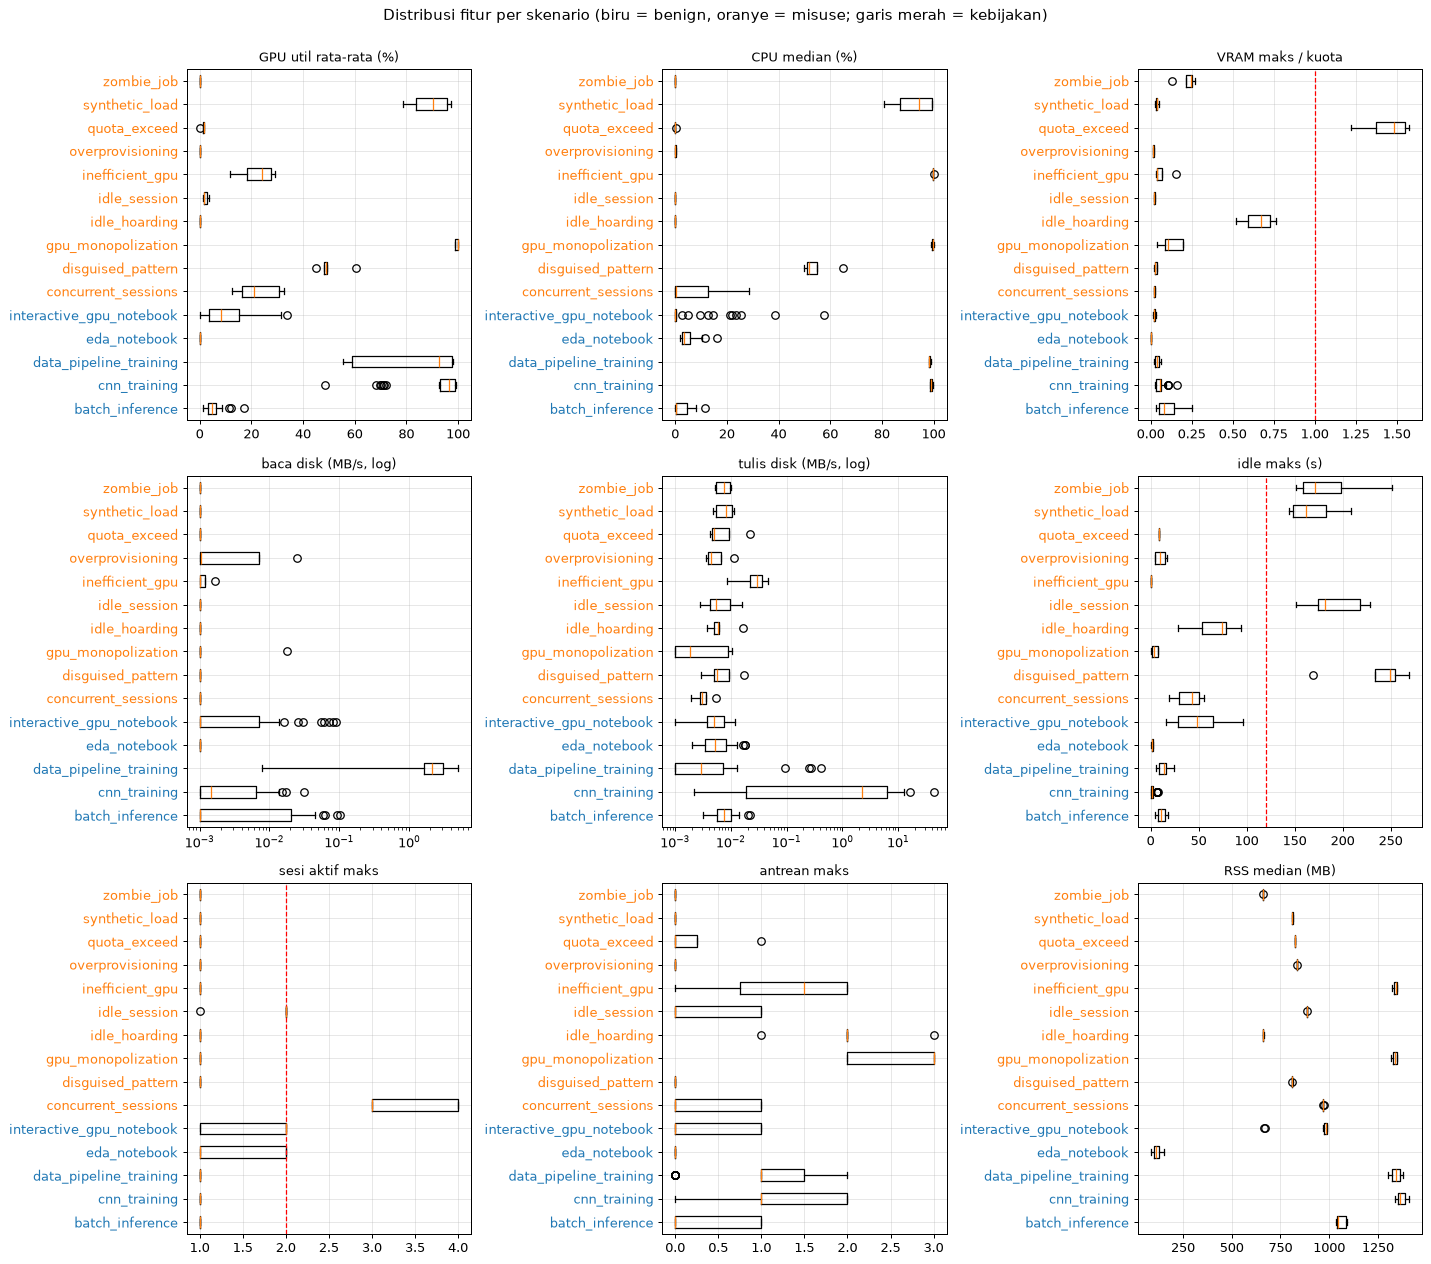

In [8]:
KEY = [("gpu_util_mean", "GPU util rata-rata (%)", False), ("cpu_median", "CPU median (%)", False),
       ("vram_quota_ratio", "VRAM maks / kuota", False), ("io_read_mbps", "baca disk (MB/s, log)", True),
       ("io_write_mbps", "tulis disk (MB/s, log)", True), ("last_activity_max", "idle maks (s)", False),
       ("sessions_max", "sesi aktif maks", False), ("queue_max", "antrean maks", False),
       ("mem_rss_median", "RSS median (MB)", False)]
order = sf.groupby("job_type").label.first().sort_values().index
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, (col, title, logx) in zip(axes.flat, KEY):
    data = [sf.loc[sf.job_type == j, col].dropna().clip(lower=1e-3 if logx else None) for j in order]
    ax.boxplot(data, orientation="horizontal", tick_labels=[SHORT[j] for j in order], showfliers=True)
    if logx:
        ax.set_xscale("log")
    if col == "last_activity_max":
        ax.axvline(policy["idle_timeout_sec"], color="red", ls="--", lw=1, label="ambang idle")
    if col == "sessions_max":
        ax.axvline(policy["max_concurrent_sessions"], color="red", ls="--", lw=1, label="batas sesi")
    if col == "vram_quota_ratio":
        ax.axvline(1.0, color="red", ls="--", lw=1, label="kuota")
    ax.set_title(title, fontsize=10)
for ax in axes.flat:
    for lbl in ax.get_yticklabels():
        lbl.set_color("tab:orange" if ("misuse_" + lbl.get_text()) in SHORT else "tab:blue")
plt.suptitle("Distribusi fitur per skenario (biru = benign, oranye = misuse; garis merah = kebijakan)", y=1.0)
plt.tight_layout(); plt.show()

## 4. Contoh time series per skenario
Satu sesi verified per skenario, dengan durasi paling dekat ke median skenarionya. Garis: utilisasi GPU,
CPU (dipotong di 150%), dan VRAM sebagai % kuota sesi.

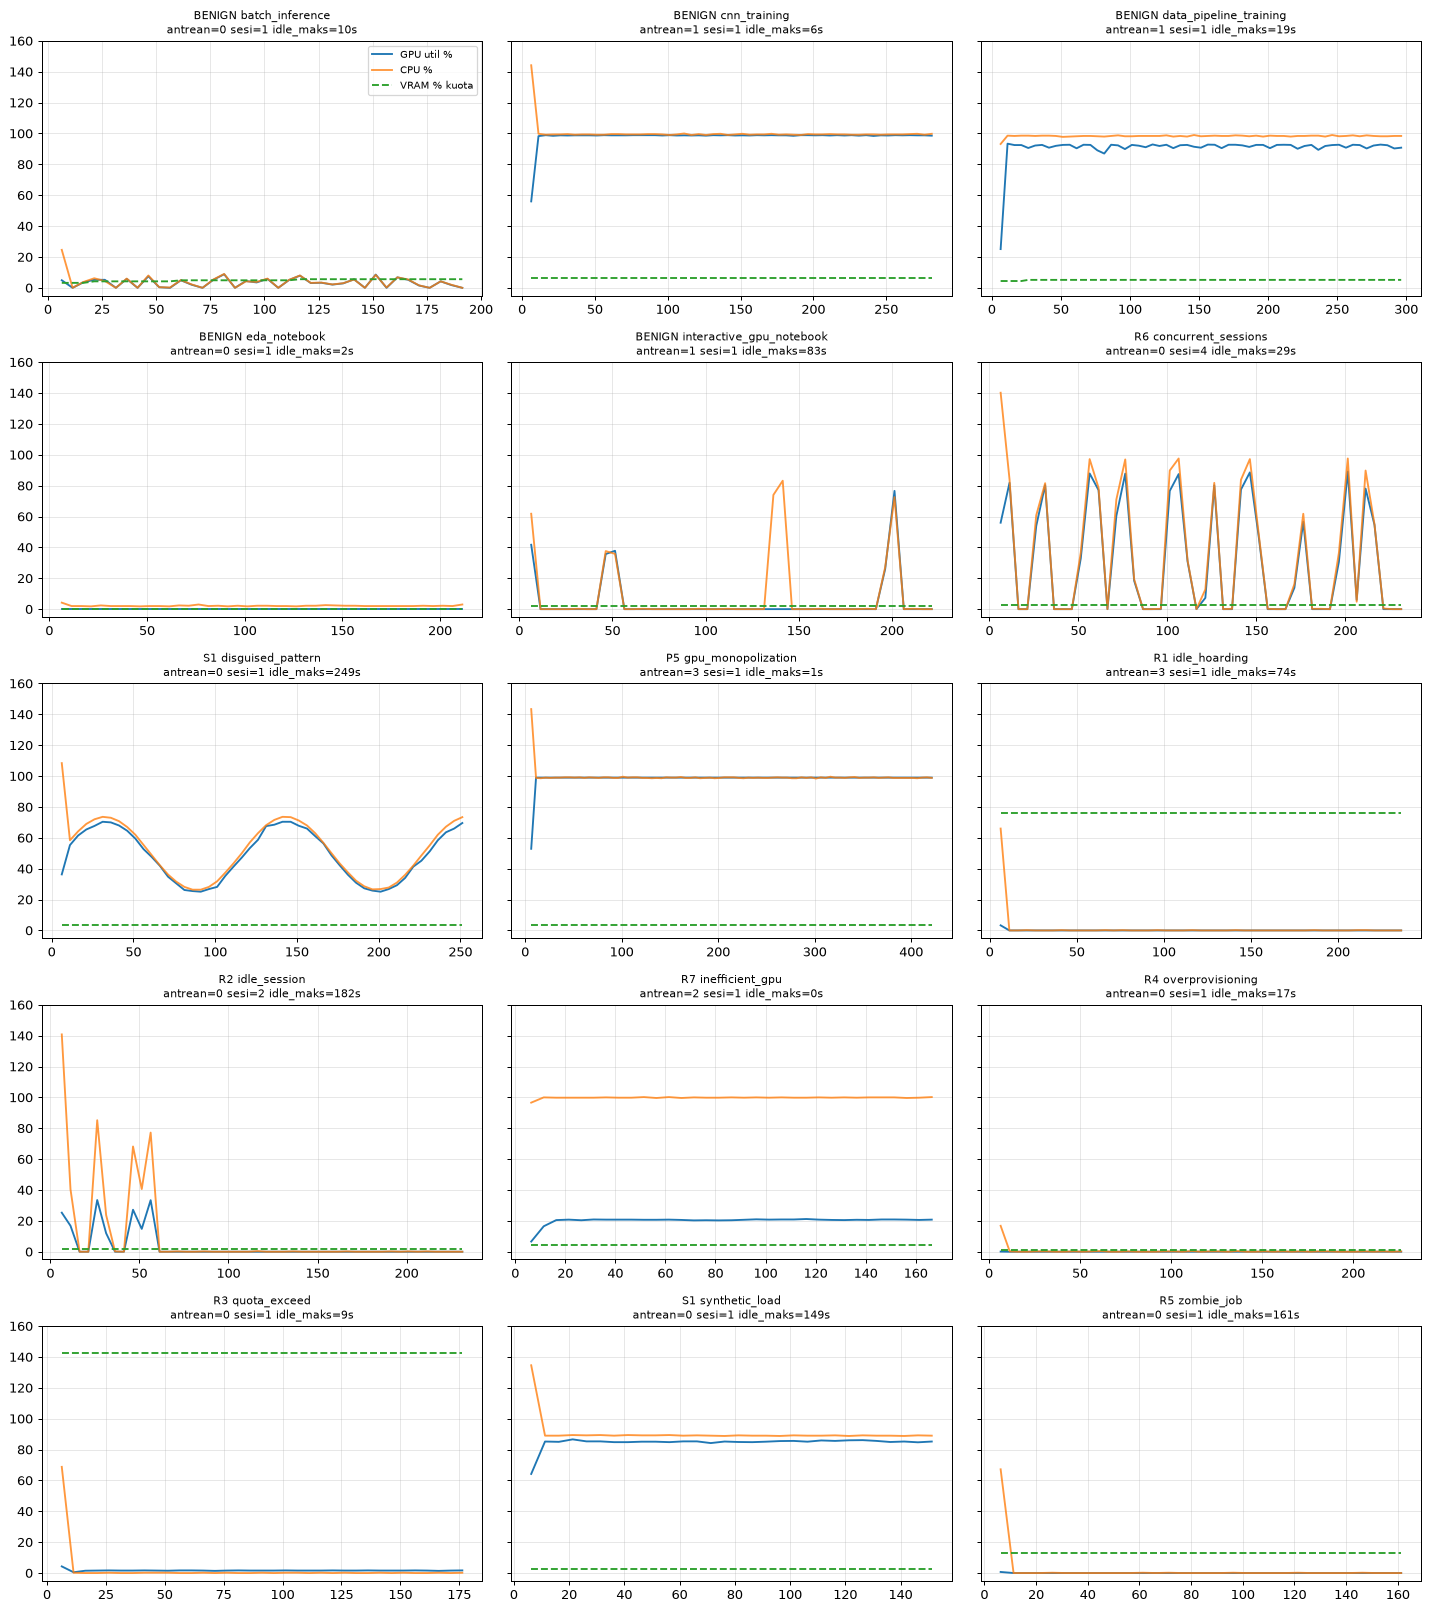

In [9]:
rep = {}
for j, g in sf[sf.verified].groupby("job_type"):
    rep[j] = (g.duration_s - g.duration_s.median()).abs().idxmin()
jobs = list(order)
fig, axes = plt.subplots(5, 3, figsize=(16, 18), sharey=True)
for ax, j in zip(axes.flat, jobs):
    sid = rep[j]
    d = df[df.session_id == sid].sort_values("session_age_sec")
    ax.plot(d.session_age_sec, d.gpu_util_pct, label="GPU util %")
    ax.plot(d.session_age_sec, d.cpu_pct.clip(upper=150), label="CPU %", alpha=0.8)
    ax.plot(d.session_age_sec, 100 * d.gpu_mem_used_mb_device / d.quota_mem_mb, label="VRAM % kuota", ls="--")
    s = sf.loc[sid]
    ax.set_title(f"{s.scenario_code} {SHORT[j]}\nantrean={s.queue_max:.0f} sesi={s.sessions_max:.0f} "
                 f"idle_maks={s.last_activity_max:.0f}s", fontsize=9)
    ax.set_ylim(-5, 160)
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(jobs):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Sidecar vs Prometheus
- **Memori:** Prometheus memakai *working set* cgroup, sidecar memakai RSS proses (termasuk pustaka
  CUDA/torch bersama), sehingga nilainya tidak sama persis.
- **CPU:** `prom_cpu_pct` adalah rata-rata 60 s (`rate()[1m]`) dan di-scrape tiap 15 s, sehingga
  tertinggal dari `cpu_pct` sidecar (rata-rata 5 s).

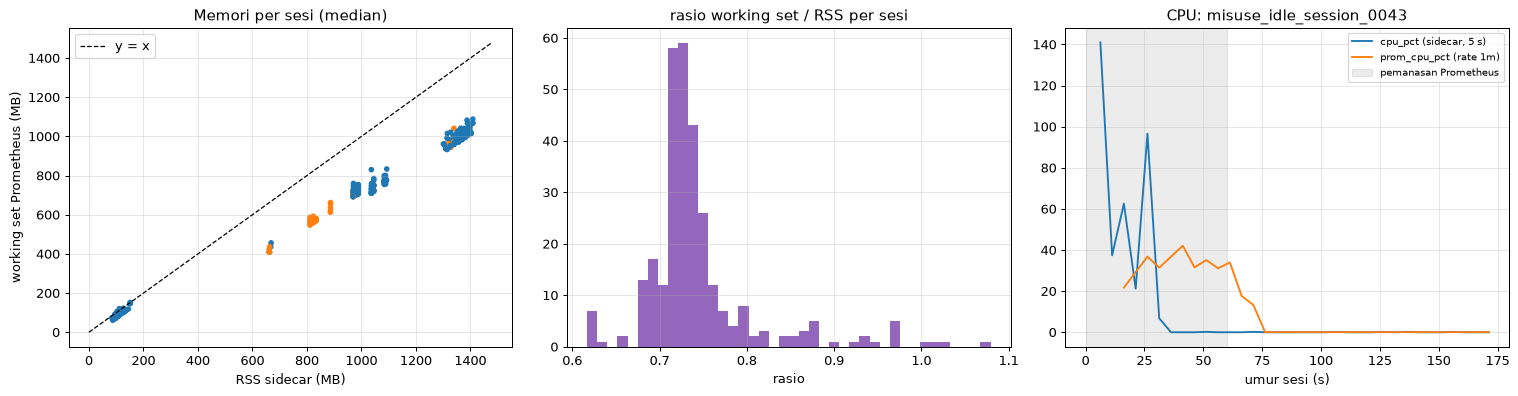

median rasio working set / RSS: 0.729


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
m = sf.dropna(subset=["prom_mem_rss_median"])
axes[0].scatter(m.mem_rss_median, m.prom_mem_rss_median, s=12, c=(m.label == "misuse").map({True: "tab:orange", False: "tab:blue"}))
lim = [0, max(m.mem_rss_median.max(), m.prom_mem_rss_median.max()) * 1.05]
axes[0].plot(lim, lim, "k--", lw=1, label="y = x"); axes[0].legend()
axes[0].set_xlabel("RSS sidecar (MB)"); axes[0].set_ylabel("working set Prometheus (MB)"); axes[0].set_title("Memori per sesi (median)")
axes[1].hist((m.prom_mem_rss_median / m.mem_rss_median).clip(0, 2), bins=40, color="tab:purple")
axes[1].set_title("rasio working set / RSS per sesi"); axes[1].set_xlabel("rasio")
ex = sf[(sf.scenario_code == "R2") & sf.verified].index[0]     # R2: CPU turun ke ~0 setelah fase aktif
d = df[df.session_id == ex].sort_values("session_age_sec")
axes[2].plot(d.session_age_sec, d.cpu_pct, label="cpu_pct (sidecar, 5 s)")
axes[2].plot(d.session_age_sec, d.prom_cpu_pct, label="prom_cpu_pct (rate 1m)")
axes[2].axvspan(0, PROM_WARMUP_SEC, color="grey", alpha=0.15, label="pemanasan Prometheus")
axes[2].set_title(f"CPU: {ex}"); axes[2].set_xlabel("umur sesi (s)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("median rasio working set / RSS:", round(float((m.prom_mem_rss_median / m.mem_rss_median).median()), 3))

## 6. Baseline berbasis aturan (`policy.json`)
Aturan sederhana sandbox: **idle** (`last_activity_age_sec` > ambang), **sesi berlebih**
(sesi aktif > batas), **lewat kuota** (VRAM > `quota_mem_mb`). Tabel menunjukkan % sesi per skenario
yang ditandai tiap aturan. Kelas yang tidak tertangkap aturan adalah yang butuh model.

In [11]:
rules = pd.DataFrame({
    "idle": sf.last_activity_max > policy["idle_timeout_sec"],
    "sesi_berlebih": sf.sessions_max > policy["max_concurrent_sessions"],
    "lewat_kuota": sf.vram_max_mb > sf.quota_mem_mb,
})
rules["salah_satu"] = rules.any(axis=1)
display((rules.groupby([sf.scenario_code, sf.job_type]).mean() * 100).round(0))
v = sf.verified
y = (sf.label == "misuse")[v]
pred = rules.salah_satu[v]
tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
print(f"sesi verified: recall misuse = {tp / y.sum():.2f} ({tp}/{int(y.sum())}), "
      f"false positive benign = {fp}/{int((~y).sum())}, precision = {tp / max(tp + fp, 1):.2f}")

idle  sesi_berlebih  lewat_kuota  salah_satu
scenario_code job_type                                                                       
BENIGN        benign_batch_inference            0.000          0.000        0.000       0.000
              benign_cnn_training               0.000          0.000        0.000       0.000
              benign_data_pipeline_training     0.000          0.000        0.000       0.000
              benign_eda_notebook               0.000          0.000        0.000       0.000
              benign_interactive_gpu_notebook   0.000          0.000        0.000       0.000
P5            misuse_gpu_monopolization         0.000          0.000        0.000       0.000
R1            misuse_idle_hoarding              0.000          0.000        0.000       0.000
R2            misuse_idle_session             100.000          0.000        0.000     100.000
R3            misuse_quota_exceed               0.000          0.000      100.000     100.000
R4            misuse_overprovisioning           0.000          0.000        0.000       0.000
R5            misuse_zombie_job               100.000          0.000        0.000     100.000
R6            misuse_concurrent_sessions        0.000        100.000        0.000     100.000
R7            misuse_inefficient_gpu            0.000          0.000        0.000       0.000
S1            misuse_disguised_pattern        100.000          0.000        0.000     100.000
              misuse_synthetic_load           100.000          0.000        0.000     100.000

sesi verified: recall misuse = 0.60 (27/45), false positive benign = 0/239, precision = 1.00


## 7. Keterpisahan fitur dan potensi jalan pintas label
AUC tiap fitur untuk membedakan **benign vs misuse** pada sesi verified (0,5 = acak; 1,0 = terpisah
sempurna). Fitur dengan AUC sangat tinggi perlu dicek: apakah mencerminkan perilaku misuse, atau
**artefak simulasi**, misalnya nilai VRAM yang selalu sama dalam satu skenario atau request CPU
yang hanya dipakai satu skenario.

In [12]:
sv = sf[sf.verified]
yv = (sv.label == "misuse").astype(int)
auc = {}
for c in FEATURES:
    x = sv[c].fillna(sv[c].median())
    if x.nunique() > 1:
        a = roc_auc_score(yv, x)
        auc[c] = {"AUC": a, "keterpisahan": max(a, 1 - a), "arah": "misuse lebih tinggi" if a >= 0.5 else "misuse lebih rendah"}
auc = pd.DataFrame(auc).T.sort_values("keterpisahan", ascending=False)
display(auc)

# Nilai yang (nyaris) konstan per skenario = penanda struktural
const = sf.groupby("job_type").agg(vram_median_unik=("vram_median_mb", lambda s: s.round(-1).nunique()),
                                   vram_median_modus=("vram_median_mb", lambda s: s.round(-1).mode().iloc[0]),
                                   cpu_request_unik=("cpu_request", lambda s: sorted(s.dropna().unique().tolist())),
                                   durasi_min=("duration_s", "min"), durasi_maks=("duration_s", "max"))
display(const)

,AUC,keterpisahan,arah
last_activity_max,0.735,0.735,misuse lebih tinggi
io_read_mbps,0.298,0.702,misuse lebih rendah
mem_rss_median,0.318,0.682,misuse lebih rendah
activity_resets,0.325,0.675,misuse lebih rendah
cpu_std,0.327,0.673,misuse lebih rendah
prom_mem_rss_median,0.328,0.672,misuse lebih rendah
vram_quota_ratio,0.622,0.622,misuse lebih tinggi
vram_median_mb,0.609,0.609,misuse lebih tinggi
vram_max_mb,0.607,0.607,misuse lebih tinggi
prom_cpu_pct_median,0.403,0.597,misuse lebih rendah


,vram_median_unik,vram_median_modus,cpu_request_unik,durasi_min,durasi_maks
job_type,,,,,
benign_batch_inference,38,360.000,"[1.0, 2.0]",96.400,301.400
benign_cnn_training,12,750.000,"[1.0, 2.0]",96.300,441.300
benign_data_pipeline_training,17,340.000,"[1.0, 2.0]",101.300,441.400
benign_eda_notebook,1,0.000,"[1.0, 2.0]",96.400,291.400
benign_interactive_gpu_notebook,4,280.000,"[1.0, 2.0]",101.400,331.400
misuse_concurrent_sessions,1,230.000,"[1.0, 2.0]",131.300,296.300
misuse_disguised_pattern,2,220.000,[2.0],171.300,271.300
misuse_gpu_monopolization,4,"2,420.000","[1.0, 2.0]",346.300,511.300
misuse_idle_hoarding,5,"4,240.000","[1.0, 2.0]",141.300,271.300


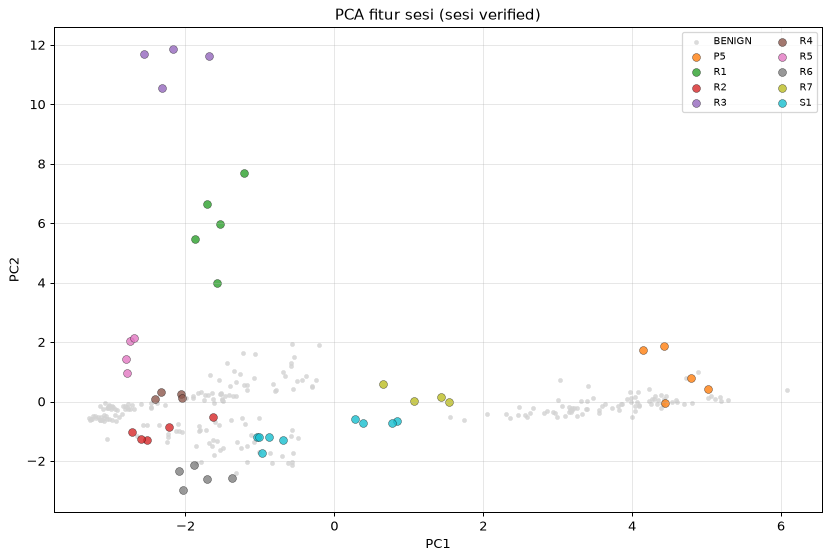

In [13]:
X = sv[FEATURES].fillna(sv[FEATURES].median())
X = X.loc[:, X.nunique() > 1]
Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(figsize=(11, 7))
codes = sorted(sv.scenario_code.unique())
cmap = plt.get_cmap("tab10")
for i, c in enumerate(codes):
    mask = (sv.scenario_code == c).to_numpy()
    ax.scatter(Z[mask, 0], Z[mask, 1], s=40 if c != "BENIGN" else 12, label=c, alpha=0.8,
               color="lightgrey" if c == "BENIGN" else cmap(i % 10), edgecolor="k" if c != "BENIGN" else None, lw=0.3)
ax.set_title("PCA fitur sesi (sesi verified)"); ax.legend(ncol=2, fontsize=8); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.show()

## 8. Hard negative: sesi benign yang mirip R7
R7 (`misuse_inefficient_gpu`) didefinisikan sebagai CPU ~1 core penuh dengan GPU rendah. Di GPU cepat,
training benign dengan batch kecil terlihat sama (step terbatas kecepatan launch kernel); sesi seperti
itu dikeluarkan dari `dataset_verified.csv` lewat cek `bukan_pola_R7`.

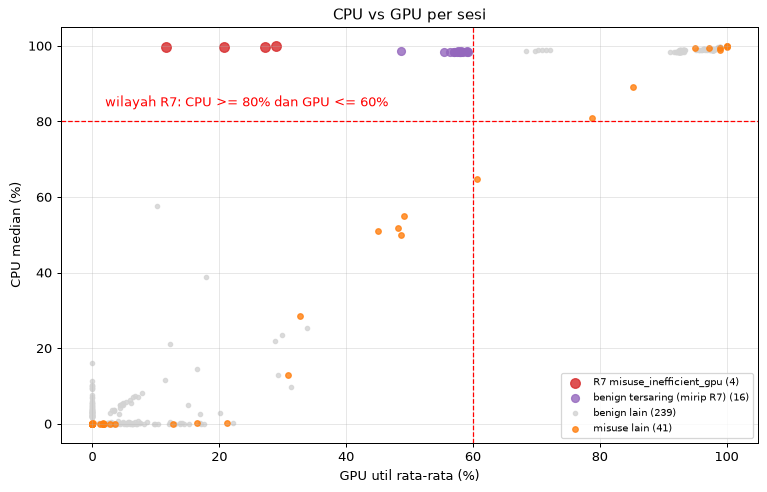

,job_type,gpu_util_mean,cpu_median,param_batch_size,param_width
session_id,,,,,
benign_data_pipeline_training_0013,benign_data_pipeline_training,57.717,98.600,64.000,NaN
benign_data_pipeline_training_0026,benign_data_pipeline_training,59.030,98.500,64.000,NaN
benign_data_pipeline_training_0056,benign_data_pipeline_training,59.158,98.400,64.000,NaN
benign_data_pipeline_training_0058,benign_data_pipeline_training,59.105,98.600,64.000,NaN
benign_data_pipeline_training_0123,benign_data_pipeline_training,57.467,98.400,64.000,NaN
benign_data_pipeline_training_0144,benign_data_pipeline_training,57.764,98.400,64.000,NaN
benign_data_pipeline_training_0146,benign_data_pipeline_training,58.388,98.400,64.000,NaN
benign_cnn_training_0154,benign_cnn_training,48.611,98.600,32.000,16.000
benign_data_pipeline_training_0182,benign_data_pipeline_training,58.193,98.400,64.000,NaN


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
groups = {
    "R7 misuse_inefficient_gpu": sf.job_type == "misuse_inefficient_gpu",
    "benign tersaring (mirip R7)": (sf.label == "benign") & ~sf.verified,
    "benign lain": (sf.label == "benign") & sf.verified,
    "misuse lain": (sf.label == "misuse") & (sf.job_type != "misuse_inefficient_gpu"),
}
style = {"R7 misuse_inefficient_gpu": ("tab:red", 60), "benign tersaring (mirip R7)": ("tab:purple", 40),
         "benign lain": ("lightgrey", 12), "misuse lain": ("tab:orange", 20)}
for name, mask in groups.items():
    ax.scatter(sf.loc[mask, "gpu_util_mean"], sf.loc[mask, "cpu_median"], label=f"{name} ({int(mask.sum())})",
               color=style[name][0], s=style[name][1], alpha=0.8)
ax.axvline(60, color="red", ls="--", lw=1); ax.axhline(80, color="red", ls="--", lw=1)
ax.text(2, 84, "wilayah R7: CPU >= 80% dan GPU <= 60%", color="red")
ax.set_xlabel("GPU util rata-rata (%)"); ax.set_ylabel("CPU median (%)"); ax.legend(fontsize=8)
ax.set_title("CPU vs GPU per sesi"); plt.show()
display(sf.loc[groups["benign tersaring (mirip R7)"], ["job_type", "gpu_util_mean", "cpu_median"]]
        .join(df.groupby("session_id")[["param_batch_size", "param_width"]].first()))

## 9. Korelasi antar fitur
Korelasi Spearman antar fitur sesi (sesi verified). Pasangan dengan |r| mendekati 1 membawa
informasi yang sama; cukup pilih salah satu untuk model.

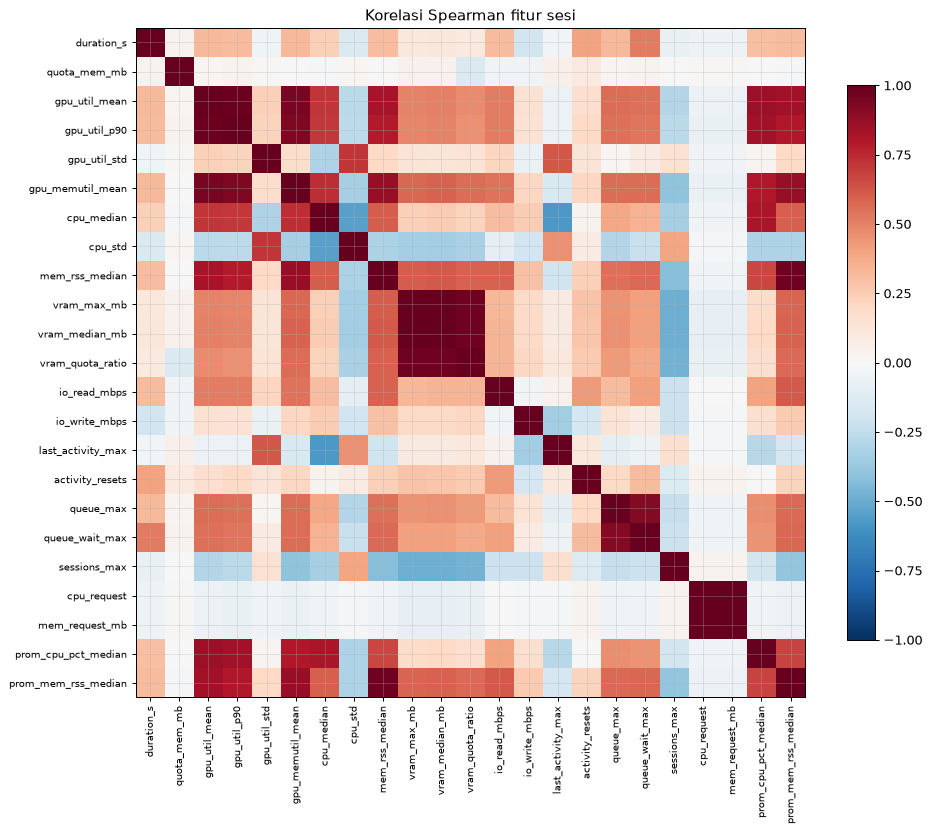

,,r
cpu_request,mem_request_mb,1.000
vram_max_mb,vram_median_mb,0.998
gpu_util_mean,gpu_util_p90,0.981
mem_rss_median,prom_mem_rss_median,0.975
vram_max_mb,vram_quota_ratio,0.971
vram_median_mb,vram_quota_ratio,0.970
gpu_util_mean,gpu_memutil_mean,0.953
gpu_util_p90,gpu_memutil_mean,0.936
queue_max,queue_wait_max,0.915


In [15]:
cols = [c for c in FEATURES if sv[c].nunique() > 1]
corr = sv[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=8); ax.set_yticks(range(len(cols)), cols, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Korelasi Spearman fitur sesi"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
display(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).to_frame("r"))

## 10. Ringkasan untuk rekayasa fitur
Hal yang perlu dibawa ke `detector/common/feature_engineering.py`:

1. **Buang kolom konstan/redundan** (bagian 2): `gpu_mem_used_mb_process` (selalu 0 di WSL2, padahal
   termasuk fitur bawaan detector), `num_alive_processes`, `gpu_mem_total_mb`, `prom_restarts_total`,
   kolom limit, dan `gpu_alloc_sec` (= `session_age_sec`). Jangan pernah memakai `param_*`.
2. **Abaikan awal sesi untuk kolom `prom_*`** (bagian 2 dan 5): kosong atau basi sampai ±60 s.
3. **Ubah IO kumulatif menjadi laju** (bagian 3). Nilai awal kumulatif bergantung pada page cache dan
   urutan run, bukan perilaku.
4. **Tambahkan fitur konteks** (bagian 3 dan 6): idle (`last_activity_age_sec`), sesi aktif, antrean,
   dan rasio VRAM terhadap kuota. Banyak misuse didefinisikan oleh konteks, bukan besar pemakaian.
5. **Waspadai jalan pintas** (bagian 7): nilai VRAM yang konstan per skenario, request CPU yang hanya
   dipakai R4, dan rentang durasi per skenario. Uji model juga tanpa fitur-fitur itu.
6. **Hard negative R7** (bagian 8): 16 sesi benign mirip R7 dikeluarkan dari verified; bisa dipakai
   sebagai uji ketahanan terpisah.
7. **Jumlah misuse kecil** (bagian 1): 4–5 sesi per skenario. Pakai pembagian data per sesi yang
   distratifikasi dan diulang beberapa seed; pertimbangkan run tambahan khusus misuse.